# Stage 5 — Baselines You Must Beat

Compute two leakage-safe reference forecasts on the 2023 test year:

1. **Persistence:** predict every horizon with the issue-time `log_chl_t0`.
2. **Climatology:** predict from pre-test pixel-by-calendar-month CHL statistics with leakage-safe fallbacks.

Both methods are scored on the exact common persistence mask: finite target and finite issue-time CHL. At each horizon, the lower-RMSE method is the strongest baseline used by Notebook 6.


## 5.0 — Load the sample & the feature manifest

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

PROC_DIR = Path("data/processed")
FIG_DIR = Path("figs")
FIG_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_PATH = PROC_DIR / "supervised_sample.parquet"
MANIFEST_PATH = PROC_DIR / "feature_manifest.json"
SCORES_PATH = PROC_DIR / "baseline_scores.csv"
SPLIT_PATH = PROC_DIR / "split_manifest.json"

for path in (SAMPLE_PATH, MANIFEST_PATH):
    assert path.exists(), f"Missing {path}"

df = (
    pd.read_parquet(SAMPLE_PATH)
    .sort_values(["time", "latitude", "longitude"])
    .reset_index(drop=True)
)

df["time"] = pd.to_datetime(df["time"])

manifest = json.loads(MANIFEST_PATH.read_text())

HORIZONS = manifest["horizons"]
TARGET_COLS = manifest["target_cols"]

print(f"Rows       : {len(df):,}")
print(f"Time range : {df.time.min().date()} → {df.time.max().date()}")
print("Rows/year  :")
print(df["time"].dt.year.value_counts().sort_index())
print(f"Horizons   : {HORIZONS}")

Rows       : 360,000
Time range : 2021-01-01 → 2023-12-30
Rows/year  :
time
2021    120000
2022    120000
2023    120000
Name: count, dtype: int64
Horizons   : [1, 2, 3, 4, 5, 6, 7]


## 5.1 — Calendar-year chronological split

Use complete seasons: 2021 for model fitting, 2022 for validation/early stopping, and 2023 as the untouched test year. Notebook 6 selects tree counts with 2021/2022, then refits on permissible 2021–2022 rows before testing once on 2023. The split manifest records this contract and the horizon-aware boundary purge.


In [2]:
# Use complete calendar years so every split contains all seasons.
train = df[df["time"].dt.year == 2021].copy()
val = df[df["time"].dt.year == 2022].copy()
test = df[df["time"].dt.year == 2023].copy()

# Notebook 6 will use 2021 for early-stopping training, 2022 for
# validation, then refit on 2021–2022 before evaluating 2023.
reference = pd.concat([train, val], ignore_index=True)

for name, part in [
    ("train", train),
    ("validation", val),
    ("test", test),
]:
    if part.empty:
        raise RuntimeError(f"{name} split is empty")

print(
    f"train : {train.time.min().date()} → "
    f"{train.time.max().date()} ({len(train):,} rows)"
)
print(
    f"val   : {val.time.min().date()} → "
    f"{val.time.max().date()} ({len(val):,} rows)"
)
print(
    f"test  : {test.time.min().date()} → "
    f"{test.time.max().date()} ({len(test):,} rows)"
)
print(
    f"refit : {reference.time.min().date()} → "
    f"{reference.time.max().date()} ({len(reference):,} rows)"
)

train : 2021-01-01 → 2021-12-31 (120,000 rows)
val   : 2022-01-01 → 2022-12-31 (120,000 rows)
test  : 2023-01-01 → 2023-12-30 (120,000 rows)
refit : 2021-01-01 → 2022-12-31 (240,000 rows)


## 5.2 — Persistence baseline

Persistence predicts `target_h{h}` with `log_chl_t0`. Because the supervised sample retains cloudy issue times, persistence is not defined everywhere. Its comparison mask therefore requires both a finite target and finite current CHL; XGBoost uses this exact mask for baseline comparisons while also reporting a broader all-observed-target score.


In [3]:
from sklearn.metrics import mean_squared_error, r2_score

def score_arrays(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if len(y_true) == 0:
        return {"rmse": np.nan, "r2": np.nan, "n": 0}

    return {
        "rmse": float(
            np.sqrt(mean_squared_error(y_true, y_pred))
        ),
        "r2": float(r2_score(y_true, y_pred)),
        "n": int(len(y_true)),
    }

persistence_pred = test["log_chl_t0"].to_numpy()

# All methods, including XGBoost in Notebook 6, must use this exact
# common mask when being compared with persistence.
common_masks = {}
persistence_rows = []

for h in HORIZONS:
    target_col = f"target_h{h}"
    y = test[target_col].to_numpy()

    common = (
        np.isfinite(y)
        & np.isfinite(persistence_pred)
    )
    common_masks[h] = common

    result = score_arrays(
        y[common],
        persistence_pred[common],
    )

    persistence_rows.append({
        "method": "persistence",
        "horizon": h,
        "evaluation_scope": "common_persistence_mask",
        **result,
    })

    print(
        f"H+{h}  RMSE={result['rmse']:.4f}  "
        f"R²={result['r2']:.4f}  N={result['n']:,}"
    )

H+1  RMSE=0.1037  R²=0.8497  N=50,166
H+2  RMSE=0.1224  R²=0.7988  N=47,278
H+3  RMSE=0.1332  R²=0.7542  N=45,124
H+4  RMSE=0.1375  R²=0.7347  N=44,819
H+5  RMSE=0.1467  R²=0.6893  N=44,218
H+6  RMSE=0.1536  R²=0.6620  N=44,020
H+7  RMSE=0.1559  R²=0.6650  N=44,010


## 5.3 — Climatology baseline from pre-test CHL

Fit a pixel-by-calendar-month mean in log-CHL space using only 2021–2022. Missing pixel-month lookups fall back first to that pixel's pre-test annual mean and then to the basin-wide mean for the requested month. Score climatology on the same rows as persistence so RMSE and R² are directly comparable.


In [4]:
import xarray as xr

CHL_PATH = Path("data/raw/chl_malta_2021_2023.nc")

# Chunking prevents the full 225 MB cube from being loaded at once.
chl_ds = xr.open_dataset(
    CHL_PATH,
    chunks={"time": 31},
)

chl_raw = chl_ds["CHL"].sel(
    time=slice("2021-01-01", "2022-12-31")
)

valid_min = float(chl_raw.attrs.get("valid_min", 0.0))
valid_max = float(chl_raw.attrs.get("valid_max", np.inf))

chl_reference = chl_raw.where(
    (chl_raw > 0)
    & (chl_raw >= valid_min)
    & (chl_raw <= valid_max)
)

log_chl_reference = np.log10(chl_reference)

# Primary climatology: pixel × calendar month, fitted using only
# pre-test observations from 2021–2022.
clim_month = (
    log_chl_reference
    .groupby("time.month")
    .mean("time", skipna=True)
    .astype("float32")
    .load()
)

# First fallback: that pixel's annual reference-period mean.
pixel_mean = (
    log_chl_reference
    .mean("time", skipna=True)
    .astype("float32")
    .load()
)

# Final fallback: basin-wide mean for the requested month.
basin_month = clim_month.mean(
    ("latitude", "longitude"),
    skipna=True,
)

chl_ds.close()

# Vectorised lookup for the sampled 2023 test rows.
row_month = xr.DataArray(
    test["time"].dt.month.to_numpy(),
    dims="row",
)
row_lat = xr.DataArray(
    test["latitude"].to_numpy(),
    dims="row",
)
row_lon = xr.DataArray(
    test["longitude"].to_numpy(),
    dims="row",
)

pixel_month_pred = clim_month.sel(
    month=row_month,
    latitude=row_lat,
    longitude=row_lon,
).values

pixel_mean_pred = pixel_mean.sel(
    latitude=row_lat,
    longitude=row_lon,
).values

basin_month_pred = basin_month.sel(
    month=row_month,
).values

# Hierarchical fallback; no test observations enter any level.
clim_pred = np.where(
    np.isfinite(pixel_month_pred),
    pixel_month_pred,
    np.where(
        np.isfinite(pixel_mean_pred),
        pixel_mean_pred,
        basin_month_pred,
    ),
)

test["clim_pred"] = clim_pred

print(
    "Missing primary pixel-month lookup : "
    f"{np.mean(~np.isfinite(pixel_month_pred)) * 100:.3f}%"
)
print(
    "Missing after all fallbacks         : "
    f"{np.mean(~np.isfinite(clim_pred)) * 100:.3f}%"
)

climatology_rows = []

for h in HORIZONS:
    target_col = f"target_h{h}"
    y = test[target_col].to_numpy()
    common = common_masks[h]

    if not np.isfinite(clim_pred[common]).all():
        raise RuntimeError(
            f"Climatology is undefined on the H+{h} common mask"
        )

    result = score_arrays(
        y[common],
        clim_pred[common],
    )

    climatology_rows.append({
        "method": "climatology",
        "horizon": h,
        "evaluation_scope": "common_persistence_mask",
        **result,
    })

    print(
        f"H+{h}  RMSE={result['rmse']:.4f}  "
        f"R²={result['r2']:.4f}  N={result['n']:,}"
    )

Missing primary pixel-month lookup : 0.016%
Missing after all fallbacks         : 0.000%
H+1  RMSE=0.1350  R²=0.7454  N=50,166
H+2  RMSE=0.1359  R²=0.7520  N=47,278
H+3  RMSE=0.1347  R²=0.7485  N=45,124
H+4  RMSE=0.1348  R²=0.7453  N=44,819
H+5  RMSE=0.1346  R²=0.7383  N=44,218
H+6  RMSE=0.1335  R²=0.7447  N=44,020
H+7  RMSE=0.1339  R²=0.7528  N=44,010


## 5.4 — Save results & compare

In [5]:
scores = pd.DataFrame(
    persistence_rows + climatology_rows
)

pivot = scores.pivot(
    index="horizon",
    columns="method",
    values=["rmse", "r2", "n"],
)
pivot.columns = [
    f"{method}_{metric}"
    for metric, method in pivot.columns
]

print("Baseline scores on identical 2023 test observations:")
print(pivot.round(4).to_string())

# The model should ultimately beat whichever baseline is strongest at
# each horizon, not persistence automatically.
strongest = (
    scores.loc[
        scores.groupby("horizon")["rmse"].idxmin()
    ]
    .sort_values("horizon")
    .reset_index(drop=True)
)

print("\nStrongest baseline at each horizon:")
for _, row in strongest.iterrows():
    print(
        f"H+{int(row.horizon)}  {row.method}: "
        f"RMSE={row.rmse:.4f}, R²={row.r2:.4f}, "
        f"N={int(row.n):,}"
    )

Baseline scores on identical 2023 test observations:
         climatology_rmse  persistence_rmse  climatology_r2  persistence_r2  climatology_n  persistence_n
horizon                                                                                                  
1                  0.1350            0.1037          0.7454          0.8497        50166.0        50166.0
2                  0.1359            0.1224          0.7520          0.7988        47278.0        47278.0
3                  0.1347            0.1332          0.7485          0.7542        45124.0        45124.0
4                  0.1348            0.1375          0.7453          0.7347        44819.0        44819.0
5                  0.1346            0.1467          0.7383          0.6893        44218.0        44218.0
6                  0.1335            0.1536          0.7447          0.6620        44020.0        44020.0
7                  0.1339            0.1559          0.7528          0.6650        44010.0        4

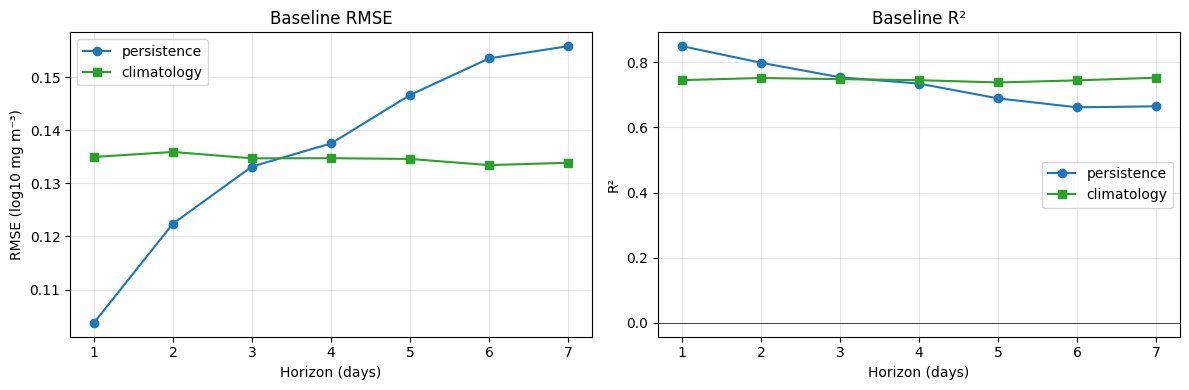

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for method, marker, color in [("persistence", "o", "#1f77b4"),
                              ("climatology", "s", "#2ca02c")]:
    sub = scores[scores.method == method].sort_values("horizon")
    axes[0].plot(sub.horizon, sub.rmse, marker=marker, color=color, label=method)
    axes[1].plot(sub.horizon, sub.r2,   marker=marker, color=color, label=method)

axes[0].set_xlabel("Horizon (days)"); axes[0].set_ylabel("RMSE (log10 mg m⁻³)")
axes[0].set_title("Baseline RMSE");   axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_xlabel("Horizon (days)"); axes[1].set_ylabel("R²")
axes[1].set_title("Baseline R²");     axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].axhline(0, color="k", linewidth=0.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "05_baselines.png", dpi=150)
plt.show()

---
## Validation Gate 5

The gate verifies the 360,000-row sample, exact 2021/2022/2023 chronology, no test observations in climatology, both baselines at all seven horizons, identical comparison counts, complete climatology fallbacks, plausible H+1 persistence, and overall weakening from H+1 to H+7.

On success it writes `baseline_scores.csv` and `split_manifest.json`. Notebook 6 must compare against the strongest baseline at each horizon on the same mask.


In [7]:
results = {}

results["new 360,000-row sample was loaded"] = (
    len(df) == 360_000
)

results["train is exactly 2021"] = (
    set(train["time"].dt.year.unique()) == {2021}
)
results["validation is exactly 2022"] = (
    set(val["time"].dt.year.unique()) == {2022}
)
results["test is exactly 2023"] = (
    set(test["time"].dt.year.unique()) == {2023}
)

results["splits are ordered and non-overlapping"] = (
    train.time.max() < val.time.min()
    and val.time.max() < test.time.min()
)

results["climatology uses no test-period observations"] = (
    pd.Timestamp("2022-12-31") < test.time.min()
)

expected_methods = {"persistence", "climatology"}

results["both baselines recorded for every horizon"] = all(
    set(group["method"]) == expected_methods
    for _, group in scores.groupby("horizon")
)

# Because both methods use the same mask, N must match exactly.
n_table = scores.pivot(
    index="horizon",
    columns="method",
    values="n",
)

results["baseline sample sizes match at every horizon"] = (
    n_table["persistence"]
    .equals(n_table["climatology"])
)

results["climatology is defined on all comparison rows"] = (
    np.isfinite(clim_pred).all()
)

pers = (
    scores[scores["method"] == "persistence"]
    .sort_values("horizon")
)

persistence_r2 = pers["r2"].to_numpy()

results["persistence R² exists at every horizon"] = (
    pers["r2"].notna().all()
)
results["persistence H+1 R² is plausible"] = (
    0.4 <= persistence_r2[0] <= 0.95
)
results["persistence weakens from H+1 to H+7"] = (
    persistence_r2[0] > persistence_r2[-1]
)

for name, ok in results.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

failed = [
    name
    for name, ok in results.items()
    if not ok
]

if failed:
    raise RuntimeError(
        "Validation Gate 5 failed:\n- "
        + "\n- ".join(failed)
    )

split_manifest = {
    "train_start": "2021-01-01",
    "train_end": "2021-12-31",
    "validation_start": "2022-01-01",
    "validation_end": "2022-12-31",
    "test_start": "2023-01-01",
    "test_end": "2023-12-31",
    "max_horizon_days": max(HORIZONS),
    "model_policy": (
        "early stopping on train 2021 / validation 2022; "
        "refit using 2021-2022; final test on 2023"
    ),
    "purge_rule": (
        "for horizon h, fitting rows must have target time "
        "no later than the end of their fitting period"
    ),
    "comparison_mask": (
        "finite target_h and finite log_chl_t0"
    ),
}

scores.to_csv(SCORES_PATH, index=False)
SPLIT_PATH.write_text(
    json.dumps(split_manifest, indent=2)
)

print("\nGate 5 PASSED.")
print(f"Scores saved → {SCORES_PATH}")
print(f"Split protocol saved → {SPLIT_PATH}")

print("\nThe bar for Notebook 6 is the strongest baseline:")
for _, row in strongest.iterrows():
    print(
        f"  H+{int(row.horizon)}  beat {row.method}: "
        f"RMSE < {row.rmse:.4f} and R² > {row.r2:.4f}"
    )

PASS  new 360,000-row sample was loaded
PASS  train is exactly 2021
PASS  validation is exactly 2022
PASS  test is exactly 2023
PASS  splits are ordered and non-overlapping
PASS  climatology uses no test-period observations
PASS  both baselines recorded for every horizon
PASS  baseline sample sizes match at every horizon
PASS  climatology is defined on all comparison rows
PASS  persistence R² exists at every horizon
PASS  persistence H+1 R² is plausible
PASS  persistence weakens from H+1 to H+7

Gate 5 PASSED.
Scores saved → data\processed\baseline_scores.csv
Split protocol saved → data\processed\split_manifest.json

The bar for Notebook 6 is the strongest baseline:
  H+1  beat persistence: RMSE < 0.1037 and R² > 0.8497
  H+2  beat persistence: RMSE < 0.1224 and R² > 0.7988
  H+3  beat persistence: RMSE < 0.1332 and R² > 0.7542
  H+4  beat climatology: RMSE < 0.1348 and R² > 0.7453
  H+5  beat climatology: RMSE < 0.1346 and R² > 0.7383
  H+6  beat climatology: RMSE < 0.1335 and R² > 0.

---
## Next: `06-XGBoost-Chrono.ipynb`

Train one leakage-purged XGBoost model per horizon. Tree counts are selected on 2022, final models are refitted on permissible 2021–2022 rows, and 2023 is scored both on the common persistence mask and on all observed targets.
